# Experimental forecast of detection recurrence — Peru
Objective: probability that a 10 km cell has at least one archived MODIS/VIIRS detection
during the target week. It does not estimate the physical probability that a fire
starts. A zero target means "no record", even though there may have been clouds or no
overpass. This difference stays explicit in the API.

The forecast for 16–22 November 2026 uses seasonality, geography and the history of one
year earlier. It has no weather data and no recent detections from November 2026.
It is an experimental seasonal reference for prioritizing review, not an operational alert.

In [1]:
from pathlib import Path
import os,json,hashlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path(os.environ.get('FIRMS_ARTIFACTS_DIR','outputs')).resolve()
P=ROOT/'23_demo_historica'
meta=json.loads((P/'forecast/forecast_metadata.json').read_text())
metrics=pd.read_csv(P/'forecast/metrics.csv')
forecast=pd.read_csv(P/'forecast/forecast_cells.csv.gz')
display(pd.Series({k:meta[k] for k in ['target','fit_period','probability_calibration_period',
    'model_selection_period','final_test_period','selected','target_week_start','target_week_end']}))

target                            at least one selected-anchor MODIS or VIIRS ar...
fit_period                                                                2013-2021
probability_calibration_period                                                 2022
model_selection_period                                                         2023
final_test_period                                                         2024-2025
selected                                               annual_lag_gradient_boosting
target_week_start                                                        2026-11-16
target_week_end                                                          2026-11-22
dtype: str

## 1. Features and evaluation without looking at the future
Training 2013–2021; probability calibration 2022; selection by Brier in 2023.
Final test 2024–2025, opened once the selection was frozen. We did not refit after seeing the test.
Features: grid coordinates, fraction of the cell area inside Peru, sine/cosine of the day
of the year, comparable activity and presence of records 52 weeks earlier, mean activity
50–54 weeks earlier and presence 104 weeks earlier. All of them exist before the prediction is issued.
The cells cover all of Peru and are defined by the official boundary, not by the places with test positives.

The spatial test blocks are excluded from training. Their observations from earlier
years can be used as features: we test areas without training examples,
but with available history. It is not a test of extrapolation to places without historical data.
All training positives are kept; negatives are sampled at 12.5 % with
inverse weights. Validation and test keep their real prevalence without subsampling.

In [2]:
display(pd.Series({'filas de entrenamiento':meta['training_rows'],
    'positivos entrenamiento':meta['training_positives'],'celdas':meta['cells'],
    'variables':', '.join(meta['features'])}))
frozen=(P/'forecast/protocol_before_test.json').read_bytes()
assert hashlib.sha256(frozen).hexdigest()==meta['frozen_protocol_sha256']
assert json.loads(frozen)['final_test_opened'] is False
assert meta['final_test_opened'] is True
display(metrics.round(4))

filas de entrenamiento                                                870061
positivos entrenamiento                                               192725
celdas                                                                 13405
variables                  x_100km, y_100km, country_area_fraction, seaso...
dtype: object

,period,split,model,rows,positive_records,prevalence,average_precision,brier_score,log_loss,roc_auc,top_5pct_capture,top_5pct_precision
0,2023,validation_seen_space,climatology,623948,23374,0.0375,0.5118,0.0260,0.0979,0.9263,0.4400,0.3296
1,2023,validation_heldout_space,climatology,73112,4893,0.0669,0.1638,0.0606,0.2281,0.7724,0.1006,0.1333
2,2023,validation_seen_space,annual_lag_gradient_boosting,623948,23374,0.0375,0.4707,0.0260,0.1008,0.9134,0.4173,0.3127
3,2023,validation_heldout_space,annual_lag_gradient_boosting,73112,4893,0.0669,0.5812,0.0400,0.1464,0.9100,0.2673,0.3543
4,2024,final_test_seen_space,climatology,623948,26084,0.0418,0.4753,0.0299,0.1101,0.9206,0.3967,0.3317
5,2024,final_test_heldout_space,climatology,73112,5078,0.0695,0.1781,0.0625,0.2324,0.7851,0.0959,0.1319
6,2024,final_test_seen_space,annual_lag_gradient_boosting,623948,26084,0.0418,0.4699,0.0290,0.1103,0.9095,0.3736,0.3123
7,2024,final_test_heldout_space,annual_lag_gradient_boosting,73112,5078,0.0695,0.5590,0.0426,0.1555,0.9016,0.2428,0.3340
8,2025,final_test_seen_space,climatology,611949,18324,0.0299,0.3784,0.0227,0.0914,0.8972,0.4707,0.2819
9,2025,final_test_heldout_space,climatology,71706,3590,0.0501,0.1074,0.0462,0.1835,0.7434,0.0760,0.0754


## 2. What the metrics mean
Average precision summarizes the ability to rank positives when they are rare
(higher is better). Brier is the squared error of the probabilities (lower is better).
Top 5 % capture: fraction of positive records inside the 5 % best-scored cells
of each week. It is not the percentage of real fires detected.
The reference is a per-cell, per-month climatology computed only on training, smoothed
with 20 weeks of national monthly information. The model uses tree boosting and a
logistic recalibration fitted only on 2022.

The model was chosen by Brier in 2023. Its result is not uniformly better: in areas seen
during 2025, climatology beats the model in both Brier and average precision.
We keep and show that result; we did not choose another version after seeing the test.

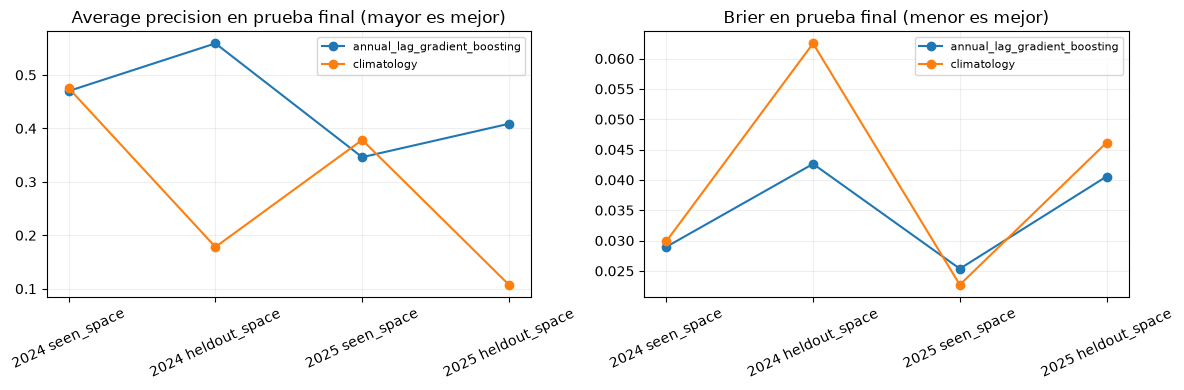

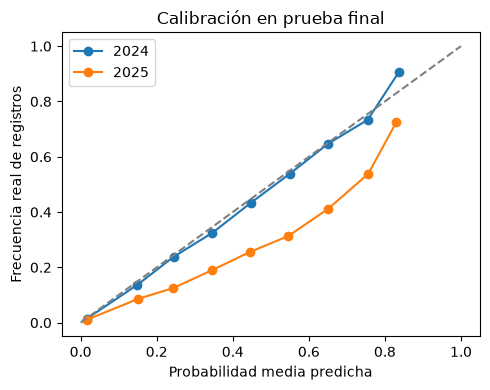

In [3]:
selected=metrics.loc[metrics.model.eq(meta['selected'])].copy()
fig,axes=plt.subplots(1,2,figsize=(12,4))
for model,g in metrics.loc[metrics.split.str.startswith('final_test')].groupby('model'):
    labels=g.period.astype(str)+' '+g.split.str.replace('final_test_','',regex=False)
    axes[0].plot(labels,g.average_precision,'o-',label=model)
    axes[1].plot(labels,g.brier_score,'o-',label=model)
axes[0].set_title('Average precision en prueba final (mayor es mejor)')
axes[1].set_title('Brier en prueba final (menor es mejor)')
for ax in axes:ax.tick_params(axis='x',rotation=25);ax.legend(fontsize=8);ax.grid(alpha=.2)
fig.tight_layout();plt.show()
bins=pd.read_csv(P/'forecast/calibration_bins.csv')
fig,ax=plt.subplots(figsize=(5,4))
for year,g in bins.groupby('year'):ax.plot(g.mean_probability,g.observed_frequency,'o-',label=str(year))
ax.plot([0,1],[0,1],'--',color='gray');ax.set(xlabel='Probabilidad media predicha',ylabel='Frecuencia real de registros',title='Calibración en prueba final')
ax.legend();fig.tight_layout();plt.show()

## 3. Map of the target week
The points show cell centres; some centres of partially clipped cells
may lie outside the boundary. The colour expresses the probability of a record under the
historical regime observed. The effect of the 2026 platform change is not known yet.
Seasonal history does not allow claiming that a locality will have a fire that week.

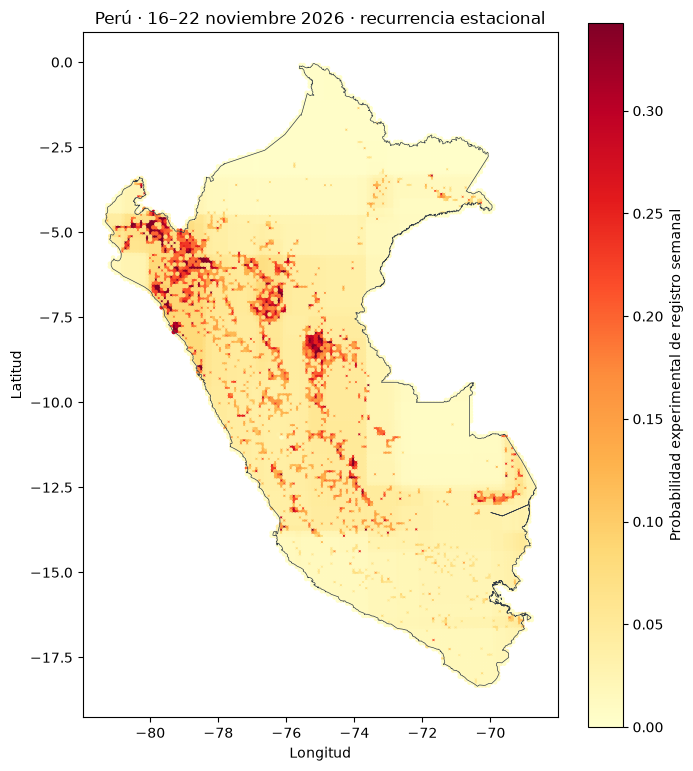

,rank,cell_id,center_lon,center_lat,record_probability,quality_flag
0,1,laea10_-38_34,-78.385610,-5.865867,0.734801,seasonal_recurrence;unknown_coverage;2026_plat...
1,2,laea10_-36_34,-78.205003,-5.867345,0.716103,seasonal_recurrence;unknown_coverage;2026_plat...
2,3,laea10_-37_34,-78.295306,-5.866616,0.716103,seasonal_recurrence;unknown_coverage;2026_plat...
3,4,laea10_10_-30,-74.037269,-11.665955,0.700496,seasonal_recurrence;unknown_coverage;2026_plat...
4,5,laea10_14_-53,-73.660449,-13.744791,0.677343,seasonal_recurrence;unknown_coverage;2026_plat...
5,6,laea10_-47_14,-79.215341,-7.665754,0.647413,seasonal_recurrence;unknown_coverage;2026_plat...
6,7,laea10_-54_25,-79.839045,-6.664425,0.597306,seasonal_recurrence;unknown_coverage;2026_plat...
7,8,laea10_10_-31,-74.036975,-11.756378,0.592192,seasonal_recurrence;unknown_coverage;2026_plat...
8,9,laea10_-49_18,-79.392920,-7.302286,0.589623,seasonal_recurrence;unknown_coverage;2026_plat...
9,10,laea10_-59_58,-80.262310,-3.676062,0.547943,seasonal_recurrence;unknown_coverage;2026_plat...


In [4]:
country=json.loads((P/'data/peru.geojson').read_text())['geometry']
polys=country['coordinates'] if country['type']=='MultiPolygon' else [country['coordinates']]
fig,ax=plt.subplots(figsize=(7,8))
for polygon in polys:
    ring=np.asarray(polygon[0]);ax.plot(ring[:,0],ring[:,1],color='#343e48',lw=.5)
sc=ax.scatter(forecast.center_lon,forecast.center_lat,c=forecast.record_probability,
              s=5,cmap='YlOrRd',vmin=0,vmax=max(.1,forecast.record_probability.quantile(.99)))
fig.colorbar(sc,ax=ax,label='Probabilidad experimental de registro semanal')
ax.set(title='Perú · 16–22 noviembre 2026 · recurrencia estacional',xlabel='Longitud',ylabel='Latitud',aspect='equal')
fig.tight_layout();plt.show()
display(forecast[['rank','cell_id','center_lon','center_lat','record_probability','quality_flag']].head(10))

## 4. Usage and pending improvements
API: `GET /v1/forecasts?limit=100` returns ranking, coordinates, week and quality warnings.
It can be filtered with `bbox=west,south,east,north` or `cell_id`; paginate with `next_offset`.
To talk about fire risk, weather, vegetation, ignitions and independent georeferenced
incidents are needed. To evaluate detection, observation masks are needed.
The comparison with the Peruvian record of occurrences is still pending: this
backtest of satellite detections is not presented as validation against events reported on the ground.

In [5]:
assert forecast.cell_id.is_unique and forecast.record_probability.between(0,1).all()
assert not meta['physical_fire_risk_probability'] and not meta['coverage_corrected']
display(pd.Series({k:meta[k] for k in ['forecast_is_seasonal_annual_recurrence',
    'current_weather_used','recent_2026_detections_used','noaa_platform_transition_2026_validated']}))
print('Ranking y probabilidades válidos dentro del contrato experimental declarado.')

forecast_is_seasonal_annual_recurrence      True
current_weather_used                       False
recent_2026_detections_used                False
noaa_platform_transition_2026_validated    False
dtype: bool

Ranking y probabilidades válidos dentro del contrato experimental declarado.
